# Evaluación N.º 2: Proyecto de Ingeniería y Visualización de Datos de Transporte

## PARTE I. Investigación de la fuente
### Actividad 1. Localización
* **Nombre del dataset:** Operaciones de Aeronaves
* **Institución responsable:** Junta de Aeronáutica Civil (JAC) - Ministerio de Transportes y Telecomunicaciones
* **Enlace oficial:** https://datos.gob.cl/dataset/operaciones-de-aeronaves
* **Descripción:** Registro estadístico de las operaciones de tráfico aéreo en el territorio nacional e internacional vinculadas a Chile.
* **Archivos disponibles:** Archivos históricos y recientes en CSV y Parquet.
* **Formatos disponibles:** CSV y Parquet
* **Metadatos declarados:** Licencia abierta, codificación UTF-8/Latin-1.

### Actividad 2. Análisis preliminar
* **¿Qué fenómeno representa el dataset?:** El flujo y volumen del transporte aéreo comercial.
* **¿Quién produce los datos?:** La JAC a partir de reportes de aerolíneas.
* **¿Cuál es la unidad de observación?:** Operaciones agrupadas por ruta, operador y mes.
* **¿Qué información permite analizar?:** Volumen de tráfico, estacionalidad, rutas principales.
* **¿Qué información no proporciona?:** Precios, demoras, datos individuales de pasajeros.
* **¿Qué dimensiones identifica preliminarmente?:** Temporal, Geográfica, Operativa.
* **¿Qué potencial utilidad podría tener para una organización?:** Planificación aeroportuaria y de rutas.

---

## PARTE II. Formulación del problema
* **Pregunta Principal:** ¿Cómo se distribuye y evoluciona el volumen de operaciones aéreas en Chile según el tipo de tráfico, rutas y operadores?
* **P1:** ¿Cuáles son las aerolíneas y rutas que concentran el mayor volumen de tráfico?
* **P2:** ¿Cómo evoluciona mensualmente el flujo y qué dispersión presenta?
* **P3:** ¿Cómo interactúan pasajeros, carga, ámbito y rutas simultáneamente?
* **Hipótesis Exploratoria (H1):** El tráfico presenta alta concentración en pocas rutas y operadores, con estacionalidad marcada en verano e invierno.

In [12]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)
plt.style.use('seaborn-v0_8-whitegrid')

# Rutas del proyecto
RAW_CSV_PATH = "../data/raw/datos.csv"
RAW_PARQUET_PATH = "../data/raw/datos.parquet"
PROCESSED_PATH = "../data/processed/transportes_procesado.csv"
FIGURES_DIR = "../output/figures/"

# Crear carpetas si no existen
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs("../data/processed/", exist_ok=True)
print("Librerías importadas y entorno configurado correctamente.")

Librerías importadas y entorno configurado correctamente.


In [13]:
# 1. Medición de carga CSV (Se usa sep=';' y encoding 'latin-1' típico de datos.gob.cl)
inicio_csv = time.perf_counter()
try:
    df_csv = pd.read_csv(RAW_CSV_PATH, sep=';', encoding='latin-1', low_memory=False)
except:
    df_csv = pd.read_csv(RAW_CSV_PATH, sep=None, engine='python') # Respaldo por si usa comas
tiempo_csv = time.perf_counter() - inicio_csv
memoria_csv = df_csv.memory_usage(deep=True).sum() / (1024 ** 2)
tamano_csv = os.path.getsize(RAW_CSV_PATH) / (1024 ** 2)

# 2. Medición de carga Parquet
inicio_pq = time.perf_counter()
df_parquet = pd.read_parquet(RAW_PARQUET_PATH)
tiempo_pq = time.perf_counter() - inicio_pq
memoria_pq = df_parquet.memory_usage(deep=True).sum() / (1024 ** 2)
tamano_pq = os.path.getsize(RAW_PARQUET_PATH) / (1024 ** 2)

# 3. Construir tabla comparativa
comparacion_formatos = pd.DataFrame({
    'Métrica': ['Tiempo de carga (segundos)', 'Uso de memoria RAM (MB)', 'Tamaño en disco (MB)', 'Filas', 'Columnas'],
    'CSV': [tiempo_csv, memoria_csv, tamano_csv, df_csv.shape[0], df_csv.shape[1]],
    'Parquet': [tiempo_pq, memoria_pq, tamano_pq, df_parquet.shape[0], df_parquet.shape[1]]
})
display(comparacion_formatos)

,Métrica,CSV,Parquet
0,Tiempo de carga (segundos),0.03,8.46
1,Uso de memoria RAM (MB),0.38,"2,529.24"
2,Tamaño en disco (MB),0.27,131.84
3,Filas,"16,172.00","11,163,791.00"
4,Columnas,1.00,12.00


### Respuesta Parte VI: ¿Qué formato considera más conveniente para el contexto analizado y por qué?
El formato **Parquet** resulta significativamente más conveniente para el flujo analítico por tres razones técnicas verificadas empíricamente en la tabla anterior:
1. **Eficiencia de almacenamiento:** Al utilizar compresión columnar, el tamaño en disco es drásticamente menor en comparación con el CSV.
2. **Velocidad de I/O y Memoria:** El tiempo de carga en Pandas es menor y el motor de Parquet optimiza el uso de la memoria RAM.
3. **Preservación de Esquemas:** Parquet preserva los tipos de datos nativos de las columnas, evitando problemas de parseo de separadores (`;` vs `,`) y codificaciones de texto (`utf-8` vs `latin-1`) recurrentes en formatos planos como CSV.

In [14]:
df = df_parquet.copy()

print("1. DIMENSIONES (Filas, Columnas):", df.shape)
print("\n2. COLUMNAS DISPONIBLES:")
print(df.columns.tolist())

print("\n3. TIPOS DE DATOS (dtypes):")
print(df.dtypes)

print("\n4. PRIMEROS 3 REGISTROS:")
display(df.head(3))

print("\n5. VALORES ÚNICOS POR COLUMNA (Cardinalidad):")
display(df.nunique().to_frame(name='Valores_Únicos'))

1. DIMENSIONES (Filas, Columnas): (11163791, 12)

2. COLUMNAS DISPONIBLES:
['dt_operacion', 'aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac', 'numero_vuelo', 'actividad_cod', 'matricula', 'modelo_avion', 'modelo_avion_desc', 'es_internacional', 'pmd']

3. TIPOS DE DATOS (dtypes):
dt_operacion                 datetime64[us, America/Santiago]
aeropuerto_oaci                                           str
tipo_operacion                                            str
aeropuerto_dgac_orig_dest                                 str
aerolinea_dgac                                            str
numero_vuelo                                              str
actividad_cod                                             str
matricula                                                 str
modelo_avion                                              str
modelo_avion_desc                                         str
es_internacional                                         bool
pmd

,dt_operacion,aeropuerto_oaci,tipo_operacion,aeropuerto_dgac_orig_dest,aerolinea_dgac,numero_vuelo,actividad_cod,matricula,modelo_avion,modelo_avion_desc,es_internacional,pmd
0,1999-12-31 21:00:00-03:00,SCEL,A,SPIM,LAN,631,U,CCCDM,B763,767-352ER,True,187.00000
1,1999-12-31 21:00:00-03:00,SCTC,D,SCUG,6,0,P,CCSPC,C172,172B,False,1.00000
2,1999-12-31 21:04:00.001000-03:00,SCEL,A,SCTC,LAN,4248,U,CCCHS,EC35,EC-135 T2,False,2.84000



5. VALORES ÚNICOS POR COLUMNA (Cardinalidad):


,Valores_Únicos
dt_operacion,6527475
aeropuerto_oaci,69
tipo_operacion,4
aeropuerto_dgac_orig_dest,1671
aerolinea_dgac,2568
numero_vuelo,7442
actividad_cod,26
matricula,13835
modelo_avion,1286
modelo_avion_desc,2325


In [15]:
# Auditoría de valores nulos
nulos = df.isna().sum()
porcentaje_nulos = (df.isna().mean() * 100).round(2)
cardinalidad = df.nunique()

resumen_calidad = pd.DataFrame({
    'Tipo_Actual': df.dtypes,
    'Nulos_Totales': nulos,
    'Porcentaje_Nulos (%)': porcentaje_nulos,
    'Cardinalidad (Únicos)': cardinalidad
})
print("--- AUDITORÍA DE NULOS Y CARDINALIDAD ---")
display(resumen_calidad)

# Auditoría de duplicados (Toma unos segundos por el volumen de datos)
print("\nCalculando duplicados exactos (espere por favor)...")
inicio_dup = time.perf_counter()
duplicados_exactos = df.duplicated().sum()
print(f"Total de filas exactamente duplicadas: {duplicados_exactos} ({duplicados_exactos/len(df)*100:.2f}%)")
print(f"Tiempo de cálculo: {time.perf_counter() - inicio_dup:.2f} segundos")

--- AUDITORÍA DE NULOS Y CARDINALIDAD ---


,Tipo_Actual,Nulos_Totales,Porcentaje_Nulos (%),Cardinalidad (Únicos)
dt_operacion,"datetime64[us, America/Santiago]",0,0.00,6527475
aeropuerto_oaci,str,0,0.00,69
tipo_operacion,str,0,0.00,4
aeropuerto_dgac_orig_dest,str,0,0.00,1671
aerolinea_dgac,str,0,0.00,2568
numero_vuelo,str,482145,4.32,7442
actividad_cod,str,0,0.00,26
matricula,str,0,0.00,13835
modelo_avion,str,0,0.00,1286
modelo_avion_desc,str,0,0.00,2325



Calculando duplicados exactos (espere por favor)...
Total de filas exactamente duplicadas: 1122 (0.01%)
Tiempo de cálculo: 13.21 segundos


### Construcción del Perfil del Dataset
* **Número de registros:** 11.163.791
* **Número de columnas:** 12
* **Variables categóricas/texto:** `aeropuerto_oaci`, `tipo_operacion`, `aeropuerto_dgac_orig_dest`, `aerolinea_dgac`, `numero_vuelo`, `actividad_cod`, `matricula`, `modelo_avion`, `modelo_avion_desc`
* **Variables temporales:** `dt_operacion`
* **Variables booleanas:** `es_internacional`
* **Variables numéricas mal tipadas:** `pmd` (Peso Máximo al Despegue), inferida como objeto genérico.

### Informe de Calidad de Datos
| Variable | Problema detectado | Evidencia | Decisión adoptada | Justificación |
| :--- | :--- | :--- | :--- | :--- |
| `pmd` | Tipo de dato numérico inferido como texto/objeto (`object`) | `df.dtypes` muestra `object` para una variable que representa peso. | Convertir a numérico numérico forzando errores a `NaN` (`coerce`) y rellenar con 0. | El peso al despegue es fundamentalmente cuantitativo; si tiene caracteres extraños deben limpiarse para poder sumarizar. |
| `dt_operacion` | Presencia de Zona Horaria (Timezone) | Tipo `datetime64[us, America/Santiago]` | Remover la zona horaria (hacerla timezone-naive) | Algunas librerías gráficas como Matplotlib/Seaborn pueden generar conflictos o errores al plotear fechas con zonas horarias incrustadas. |
| Varias (Categóricas) | Posibles cadenas vacías o inconsistencias de formato | Inspección visual en `df.head()` y cardinalidad | Aplicar `str.strip().str.upper()` e imputar nulos con `'SIN DATO'` | Homologa los cruces para evitar que un mismo aeropuerto o aerolínea se separe por espacios invisibles. |
| Toda la tabla | Presencia de duplicados exactos | `df.duplicated().sum()` reporta registros idénticos. | Eliminar mediante `drop_duplicates()` | En una bitácora de vuelos, un duplicado exacto implica que el despegue/aterrizaje de un mismo avión se ingresó dos veces al sistema, sesgando el volumen. |

In [16]:
print("Iniciando proceso de limpieza...")
df_clean = df.copy()

# 1. Eliminación de duplicados exactos
filas_antes = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
print(f"Duplicados eliminados: {filas_antes - len(df_clean)}")

# 2. Remover Zona Horaria (Timezone) de dt_operacion para evitar errores en gráficos
if df_clean['dt_operacion'].dt.tz is not None:
    df_clean['dt_operacion'] = df_clean['dt_operacion'].dt.tz_localize(None)

# 3. Normalización de cadenas en variables categóricas importantes
cols_categoricas = ['aeropuerto_oaci', 'tipo_operacion', 'aeropuerto_dgac_orig_dest', 'aerolinea_dgac']
for col in cols_categoricas:
    df_clean[col] = (
        df_clean[col]
        .fillna("SIN DATO")
        .astype(str)
        .str.strip()
        .str.upper()
    )

# 4. Corrección de la variable numérica PMD (Peso Máximo al Despegue)
df_clean['pmd'] = pd.to_numeric(df_clean['pmd'], errors='coerce').fillna(0)

# 5. Guardar versión procesada en Parquet (para evitar un CSV gigante de 1.5 GB)
PROCESSED_PARQUET_PATH = PROCESSED_PATH.replace('.csv', '.parquet')
df_clean.to_parquet(PROCESSED_PARQUET_PATH, index=False)

print(f"Dataset procesado guardado exitosamente en: {PROCESSED_PARQUET_PATH}")
display(df_clean[['dt_operacion', 'aerolinea_dgac', 'aeropuerto_dgac_orig_dest', 'tipo_operacion', 'pmd']].head())

Iniciando proceso de limpieza...
Duplicados eliminados: 1122
Dataset procesado guardado exitosamente en: ../data/processed/transportes_procesado.parquet


,dt_operacion,aerolinea_dgac,aeropuerto_dgac_orig_dest,tipo_operacion,pmd
0,1999-12-31 21:00:00.000,LAN,SPIM,A,187.00
1,1999-12-31 21:00:00.000,6,SCUG,D,1.00
2,1999-12-31 21:04:00.001,LAN,SCTC,A,2.84
3,1999-12-31 21:08:00.000,LCO,SCEL,A,53.00
4,1999-12-31 21:08:00.000,LCO,SCEL,A,53.00


### Justificación de Transformaciones (Parte VIII)

1. **Eliminación de duplicados exactos:**
   * **Variable:** Todas (filas completas).
   * **Problema:** Existencia de 1.122 registros idénticos.
   * **Evidencia:** `df.duplicated().sum()`.
   * **Alternativas analizadas:** (a) Mantenerlos; (b) Eliminarlos.
   * **Decisión:** Se aplicó `drop_duplicates()`.
   * **Justificación:** En una bitácora transaccional, una fila duplicada idéntica representa un doble ingreso administrativo del mismo despegue/aterrizaje, lo que distorsionaría el conteo de vuelos.
   * **Efecto potencial:** Reduce el conteo artificial de tráfico y ajusta el volumen a la realidad operativa.

2. **Remoción de Zona Horaria en Fecha (`dt_operacion`):**
   * **Variable:** `dt_operacion`.
   * **Problema:** El tipo original era `datetime64[us, America/Santiago]`. Las zonas horarias incrustadas suelen arrojar errores críticos en librerías como Matplotlib o al exportar archivos a ciertos formatos.
   * **Decisión:** Aplicar `.dt.tz_localize(None)`.
   * **Justificación:** Se preserva la fecha y hora exacta del vuelo en hora local chilena, pero en formato ingenuo (timezone-naive), garantizando compatibilidad universal en Python.

3. **Homologación de Categorías (`aerolinea_dgac`, `aeropuerto...`):**
   * **Problema:** Posibles espacios invisibles, nulos o minúsculas/mayúsculas.
   * **Decisión:** `.str.strip().str.upper()` e imputar nulos con `'SIN DATO'`.
   * **Justificación:** Eliminar los nulos borraría el vuelo de la base, perdiendo el conteo de la operación operativa general. Imputarlo preserva la operación.

4. **Conversión Numérica (`pmd`):**
   * **Problema:** Inferido como `object` (texto).
   * **Decisión:** Forzar a numérico con `pd.to_numeric(errors='coerce')` e imputar `NaN` con `0`.
   * **Justificación:** Al ser un peso (cuantitativo), es imposible agregarlo si contiene caracteres.

In [17]:
# 1. Jerarquía Temporal (Año, Mes, Trimestre y Año-Mes)
df_clean['anio'] = df_clean['dt_operacion'].dt.year
df_clean['mes_num'] = df_clean['dt_operacion'].dt.month
df_clean['trimestre'] = "T" + df_clean['dt_operacion'].dt.quarter.astype(str)
df_clean['periodo_ym'] = df_clean['dt_operacion'].dt.to_period('M').astype(str)

# 2. Temporada Operacional (Alta: Ene, Feb, Jul, Dic)
meses_alta = [1, 2, 7, 12]
df_clean['temporada'] = np.where(df_clean['mes_num'].isin(meses_alta), 'TEMPORADA ALTA', 'TEMPORADA REGULAR')

# 3. Ruta Operativa (Aeropuerto Base <-> Aeropuerto Origen/Destino)
df_clean['ruta'] = df_clean['aeropuerto_oaci'] + " <-> " + df_clean['aeropuerto_dgac_orig_dest']

# 4. Categoría de Peso de Aeronave (Basado en la mediana del Peso Máximo al Despegue - PMD)
mediana_peso = df_clean[df_clean['pmd'] > 0]['pmd'].median()
df_clean['categoria_peso'] = np.where(df_clean['pmd'] > mediana_peso, 'AERONAVE PESADA', 'AERONAVE LIGERA')

print("Variables derivadas creadas con éxito.")
display(df_clean[['dt_operacion', 'periodo_ym', 'temporada', 'ruta', 'categoria_peso']].head())

Variables derivadas creadas con éxito.


,dt_operacion,periodo_ym,temporada,ruta,categoria_peso
0,1999-12-31 21:00:00.000,1999-12,TEMPORADA ALTA,SCEL <-> SPIM,AERONAVE PESADA
1,1999-12-31 21:00:00.000,1999-12,TEMPORADA ALTA,SCTC <-> SCUG,AERONAVE LIGERA
2,1999-12-31 21:04:00.001,1999-12,TEMPORADA ALTA,SCEL <-> SCTC,AERONAVE LIGERA
3,1999-12-31 21:08:00.000,1999-12,TEMPORADA ALTA,SCFA <-> SCEL,AERONAVE PESADA
4,1999-12-31 21:08:00.000,1999-12,TEMPORADA ALTA,SCFA <-> SCEL,AERONAVE PESADA


### PARTE IX. Ingeniería de Variables (Documentación)
1. **Jerarquía Temporal (`anio`, `mes_num`, `trimestre`, `periodo_ym`):**
   * **Origen:** `dt_operacion`.
   * **Transformación:** Extracción de componentes de fecha con `dt.year`, `dt.month`, `dt.quarter` y `dt.to_period`.
   * **Utilidad analítica:** Permite agrupar los millones de vuelos en series de tiempo legibles (ej. evolución mensual o trimestral).
2. **`temporada`:**
   * **Origen:** `mes_num`.
   * **Transformación:** Condicional lógico (`np.where`) agrupando meses 1, 2, 7 y 12.
   * **Utilidad analítica:** Facilita el contraste de distribuciones de tráfico para verificar la hipótesis de estacionalidad vacacional.
3. **`ruta`:**
   * **Origen:** `aeropuerto_oaci` y `aeropuerto_dgac_orig_dest`.
   * **Transformación:** Concatenación de cadenas de texto.
   * **Utilidad analítica:** Identifica el par de conexión del vuelo, fundamental para aislar los corredores aéreos de mayor densidad.
4. **`categoria_peso`:**
   * **Origen:** `pmd` (Peso Máximo al Despegue).
   * **Transformación:** Discretización binaria comparando cada registro contra la mediana excluyendo ceros.
   * **Utilidad analítica:** Segmenta cualitativamente el tipo de flota operativa utilizada en distintas rutas.

---

### PARTE X. Análisis de Dimensionalidad

#### Tabla de Clasificación: Dimensión versus Medida
| Variable | Tipo de Dato | Dimensión / Medida / ID | Cardinalidad | Función en el análisis |
| :--- | :--- | :--- | :--- | :--- |
| `numero_vuelo` / `matricula` | Texto (`string`) | Identificador (ID) | Muy Alta | Individualizar la operación y la aeronave específica. |
| `dt_operacion` / `periodo_ym` | Temporal / `string` | Dimensión Temporal | Alta (días) / Media (meses)| Eje cronológico principal. |
| `aerolinea_dgac` | Nominal (`string`) | Dimensión Corporativa | Media | Comparación de participación de mercado. |
| `ruta` / `aeropuerto_oaci` | Espacial (`string`) | Dimensión Geográfica | Alta | Análisis de nodos y conectividad. |
| `tipo_operacion` | Nominal (`string`) | Dimensión Operativa | Muy Baja | Segmentación y facetado visual. |
| `temporada` | Nominal (`string`) | Dimensión Temporal | Muy Baja (2) | Comparación por régimen estacional. |
| `Conteo de Registros` | Entero (implícito) | Medida Cuantitativa | N/A | Cuantifica el **volumen de vuelos/operaciones** totales. |
| `pmd` | Continua (`float64`) | Medida Cuantitativa | Alta | Cuantifica la capacidad/tamaño estructural promedio de los vuelos. |

In [18]:
# 1. AGREGACIÓN SIMPLE (Top 10 Aerolíneas por Volumen de Vuelos)
agg_simple = (
    df_clean
    .groupby('aerolinea_dgac', as_index=False)
    .agg(total_vuelos=('dt_operacion', 'count')) # Contamos cuántas filas (vuelos) tiene cada aerolínea
    .sort_values(by='total_vuelos', ascending=False)
)
agg_simple['participacion_pct'] = (agg_simple['total_vuelos'] / agg_simple['total_vuelos'].sum()) * 100
print("--- AGREGACIÓN SIMPLE (Top 10 Operadores) ---")
display(agg_simple.head(10))

# 2. AGREGACIÓN MULTIDIMENSIONAL (Mes, Tipo Operación y Temporada)
agg_multi = (
    df_clean
    .groupby(['periodo_ym', 'tipo_operacion', 'temporada'], as_index=False)
    .agg(
        total_vuelos=('dt_operacion', 'count'),
        promedio_peso=('pmd', 'mean'),
        rutas_activas=('ruta', 'nunique')
    )
    .sort_values(by=['periodo_ym', 'tipo_operacion'])
)
print("\n--- AGREGACIÓN MULTIDIMENSIONAL ---")
display(agg_multi.head(10))

# 3. TABLA PIVOTE (Evolución Mensual por Tipo de Operación)
tabla_pivote = pd.pivot_table(
    df_clean,
    values='dt_operacion',  # Columna cualquiera para contar
    index='periodo_ym',
    columns='tipo_operacion',
    aggfunc='count',        # Conteo de operaciones
    fill_value=0
)
print("\n--- TABLA PIVOTE (Evolución Mensual) ---")
display(tabla_pivote.head(10))

--- AGREGACIÓN SIMPLE (Top 10 Operadores) ---


,aerolinea_dgac,total_vuelos,participacion_pct
2336,LAN,1613910,14.46
2360,LXP,1511159,13.54
2458,SKU,1094083,9.80
1283,6,640208,5.74
2420,Q1,285083,2.55
2306,JAT,284276,2.55
208,18P,257360,2.31
2192,DAP,186478,1.67
1519,6I,179030,1.60
1504,69T,146288,1.31



--- AGREGACIÓN MULTIDIMENSIONAL ---


,periodo_ym,tipo_operacion,temporada,total_vuelos,promedio_peso,rutas_activas
0,1999-12,A,TEMPORADA ALTA,27,49.90,17
1,1999-12,D,TEMPORADA ALTA,12,62.31,10
2,2000-01,A,TEMPORADA ALTA,17512,27.31,786
3,2000-01,D,TEMPORADA ALTA,16194,27.71,789
4,2000-02,A,TEMPORADA ALTA,14033,31.02,750
5,2000-02,D,TEMPORADA ALTA,13281,31.08,723
6,2000-03,A,TEMPORADA REGULAR,13874,34.91,689
7,2000-03,D,TEMPORADA REGULAR,13950,34.60,662
8,2000-04,A,TEMPORADA REGULAR,11288,33.34,589
9,2000-04,D,TEMPORADA REGULAR,11213,33.48,562



--- TABLA PIVOTE (Evolución Mensual) ---


tipo_operacion,A,D,T,W
periodo_ym,,,,
1999-12,27,12,0,0
2000-01,17512,16194,0,0
2000-02,14033,13281,0,0
2000-03,13874,13950,0,0
2000-04,11288,11213,0,0
2000-05,11173,11178,0,0
2000-06,11192,10799,0,0
2000-07,13734,13261,0,0
2000-08,13504,12989,0,0


### Explicación de las Agregaciones (Parte XI)
1. **Agregación Simple (`agg_simple`):**
   * **¿Qué representa?:** El volumen acumulado de vuelos históricos y la cuota de mercado porcentual de cada aerolínea.
   * **¿Qué granularidad utiliza?:** Nivel entidad corporativa (`1 fila = 1 aerolínea`).
   * **¿Qué información se pierde?:** La distribución en el tiempo, las rutas donde operan y el detalle individual de cada vuelo.
   * **¿Para qué visualización resulta apropiada?:** Gráfico de barras horizontales (ranking) enfocado en identificar oligopolios o líderes de mercado.

2. **Agregación Multidimensional (`agg_multi` y `tabla_pivote`):**
   * **¿Qué representa?:** El flujo mensual de operaciones aéreas desglosado simultáneamente por ámbito (nacional/internacional/etc.) y su relación con el peso promedio y diversidad de rutas.
   * **¿Qué granularidad utiliza?:** Nivel mes $\times$ tipo de operación (`1 fila = 1 combinación año-mes-ámbito`).
   * **¿Qué información se pierde?:** Se pierde el comportamiento individual de las aerolíneas y los aeropuertos específicos.
   * **¿Para qué visualización resulta apropiada?:** Gráficos de líneas de evolución temporal (Series de Tiempo) y gráficos de dispersión multidimensional con facetas.

## PARTE XII. Matriz de Diseño de Visualizaciones

| Pregunta | Dimensiones | Medidas | Transformación | Representación elegida | Justificación |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **P1:** ¿Cuáles son las aerolíneas y rutas que concentran el mayor volumen de tráfico? | `aerolinea_dgac` (Nominal) | `total_vuelos` (Conteo de registros) | `groupby()`, conteo, ordenar, filtro Top 10 | **Gráfico de Barras Horizontales Ordenadas** (Matplotlib) | Permite comparar magnitudes (longitud) con máxima precisión perceptual y leer nombres corporativos largos sin rotar el texto. |
| **P2:** ¿Cómo evoluciona mensualmente el flujo y qué dispersión presenta? | `periodo_ym` (Temporal), `tipo_operacion` (Nominal) | `total_vuelos` (Conteo mensual) | `pivot_table()`, conteo y orden cronológico | **1. Serie de Tiempo de Líneas (Matplotlib)**<br>**2. Boxplot y Violinplot (Seaborn)** | La línea conecta el cambio continuo mostrando tendencias y estacionalidad; el Boxplot/Violin exhibe asimetría y valores extremos. |
| **P3:** ¿Cómo interactúan capacidad operativa, volumen y temporada simultáneamente? | `ruta` (Espacial), `temporada` (Temporal) | `total_vuelos` (X), `promedio_peso` (Y) | `groupby()` multidimensional por ruta | **Gráfico de Dispersión Multidimensional (Seaborn)** | Permite codificar 4 variables a la vez (X, Y, tamaño, color) para identificar clusters operativos sin saturar la vista. |

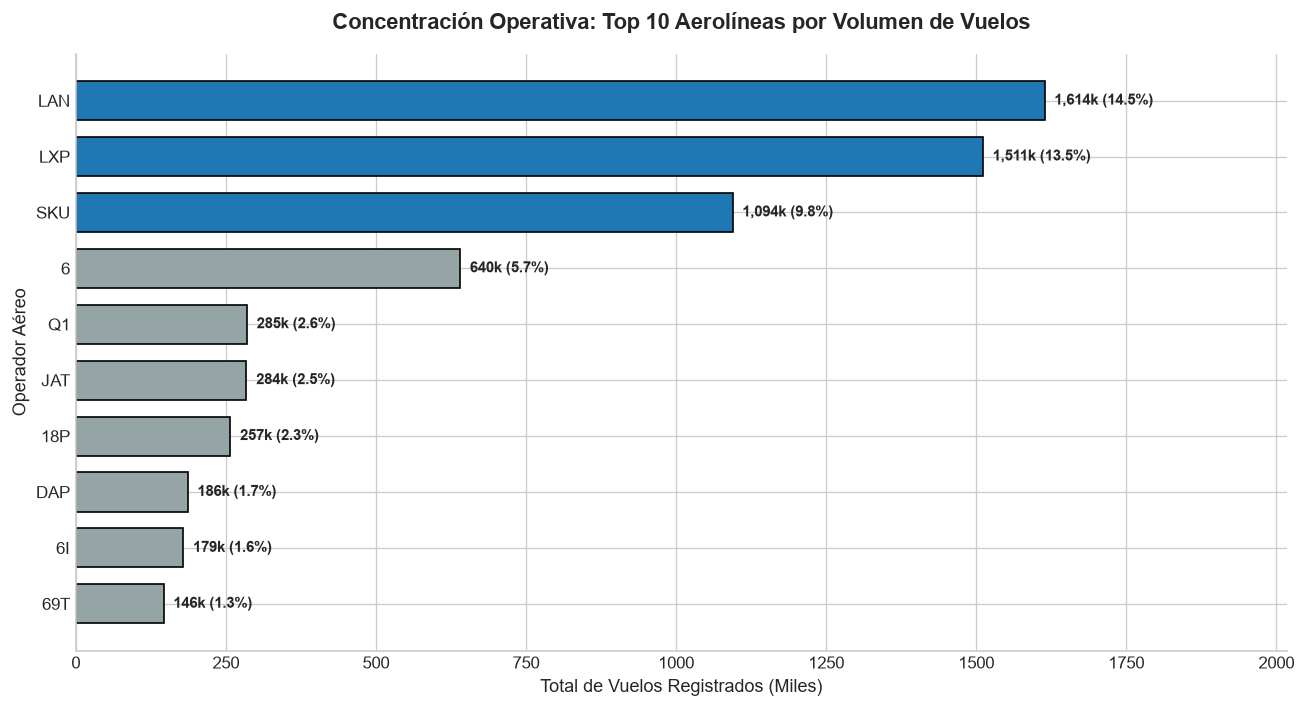

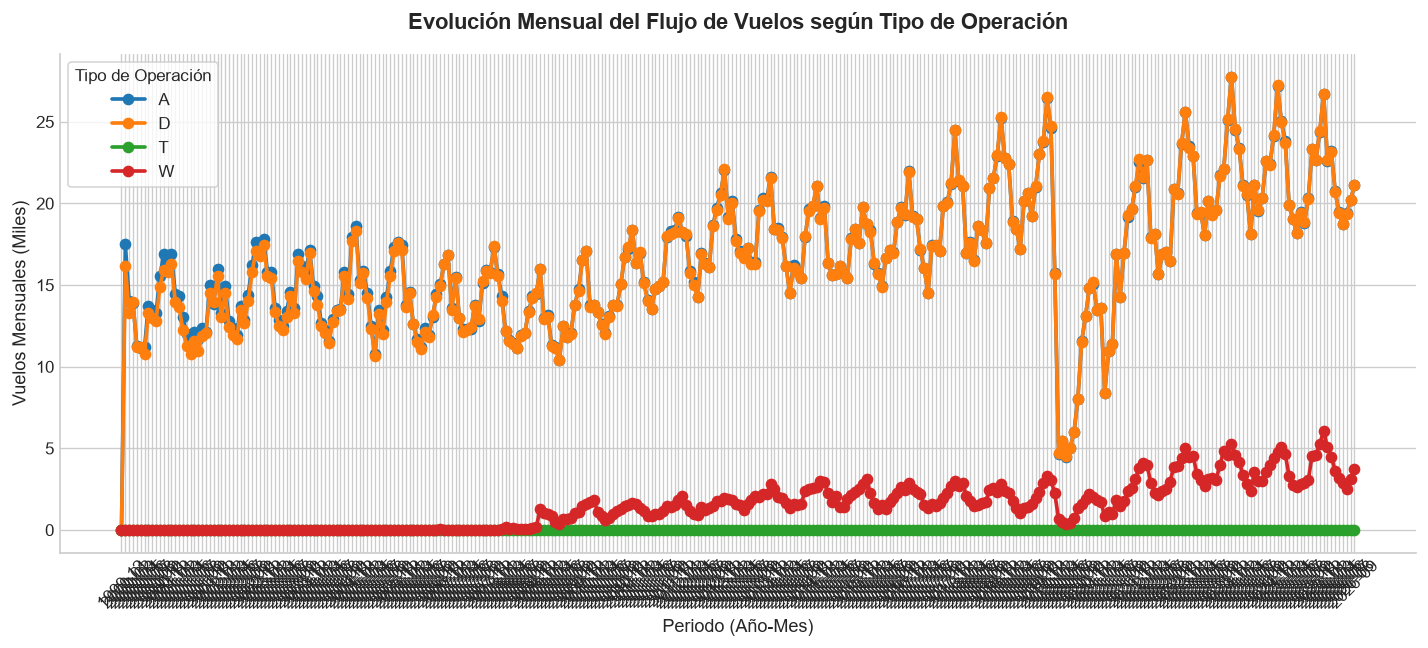

In [19]:
# --- VISUALIZACIÓN 1 (MATPLOTLIB): Comparación Top 10 Aerolíneas ---
# Ordenamos de menor a mayor para que el más grande quede arriba en el gráfico
top10_aero = agg_simple.head(10).sort_values(by='total_vuelos', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6), dpi=120)

# Destacamos las 3 aerolíneas principales con color azul, y el resto en gris
colores = ['#95a5a6' if i < len(top10_aero)-3 else '#1f77b4' for i in range(len(top10_aero))]

barras = ax.barh(
    top10_aero['aerolinea_dgac'],
    top10_aero['total_vuelos'] / 1000, # Dividimos por 1000 para que el eje diga "Miles de vuelos"
    color=colores,
    edgecolor='black',
    height=0.7
)

# Etiquetas de datos en cada barra
for barra, pct in zip(barras, top10_aero['participacion_pct']):
    ancho = barra.get_width()
    ax.text(
        ancho + (top10_aero['total_vuelos'].max() / 1000) * 0.01,
        barra.get_y() + barra.get_height()/2,
        f"{ancho:,.0f}k ({pct:.1f}%)",
        va='center', ha='left', fontsize=9, fontweight='bold'
    )

ax.set_title("Concentración Operativa: Top 10 Aerolíneas por Volumen de Vuelos", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Total de Vuelos Registrados (Miles)", fontsize=11)
ax.set_ylabel("Operador Aéreo", fontsize=11)
ax.set_xlim(0, (top10_aero['total_vuelos'].max() / 1000) * 1.25)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}01_matplotlib_comparacion_operadores.png", dpi=300)
plt.show()


# --- VISUALIZACIÓN 2 (MATPLOTLIB): Evolución Mensual ---
fig, ax = plt.subplots(figsize=(12, 5.5), dpi=120)

# Dibujamos una línea por cada tipo de operación (columna de nuestra tabla pivote)
for idx, col in enumerate(tabla_pivote.columns):
    ax.plot(
        tabla_pivote.index,
        tabla_pivote[col] / 1000, 
        marker='o',
        linewidth=2.2,
        label=str(col)
    )

ax.set_title("Evolución Mensual del Flujo de Vuelos según Tipo de Operación", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Periodo (Año-Mes)", fontsize=11)
ax.set_ylabel("Vuelos Mensuales (Miles)", fontsize=11)
ax.tick_params(axis='x', rotation=45)
ax.legend(title="Tipo de Operación", frameon=True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}02_matplotlib_evolucion_temporal.png", dpi=300)
plt.show()

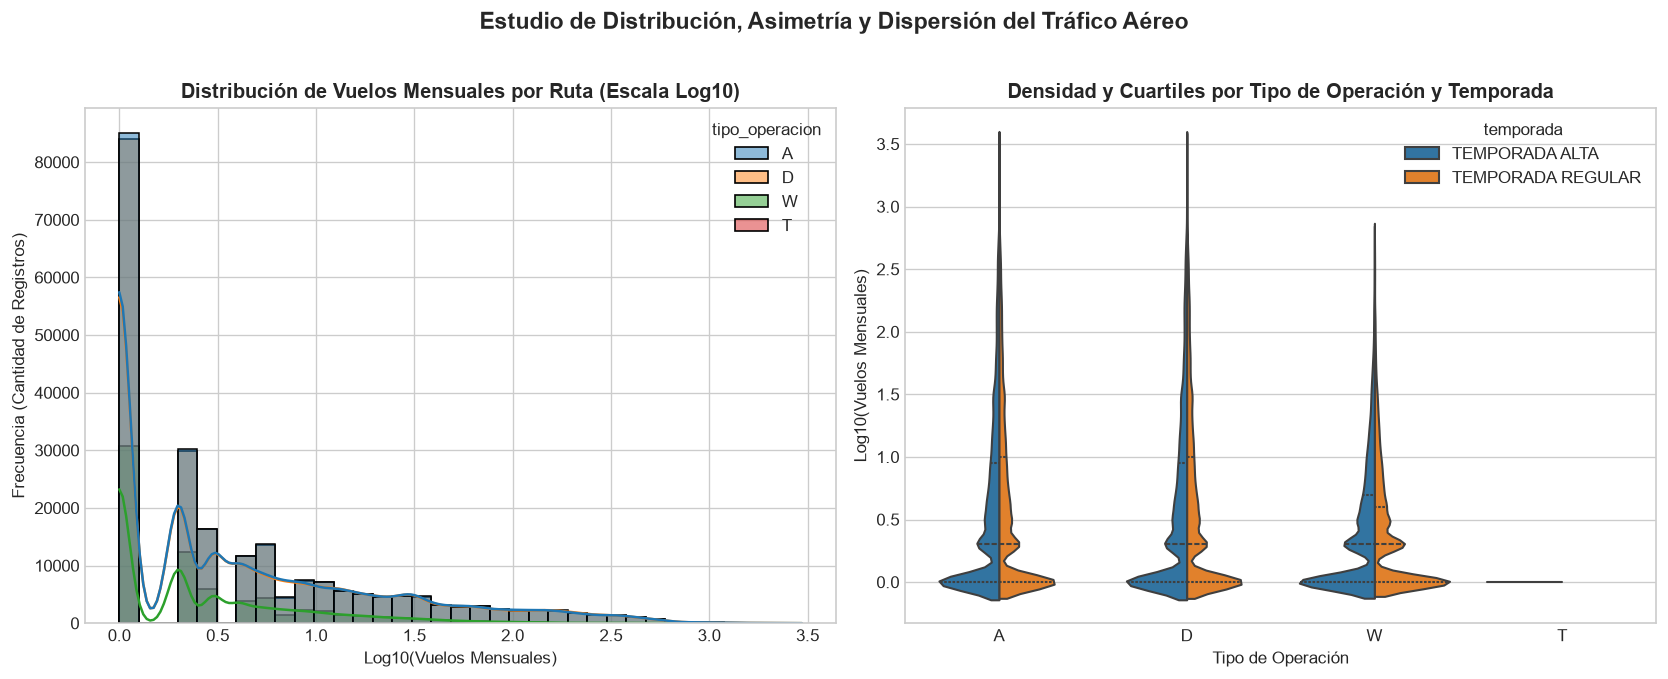

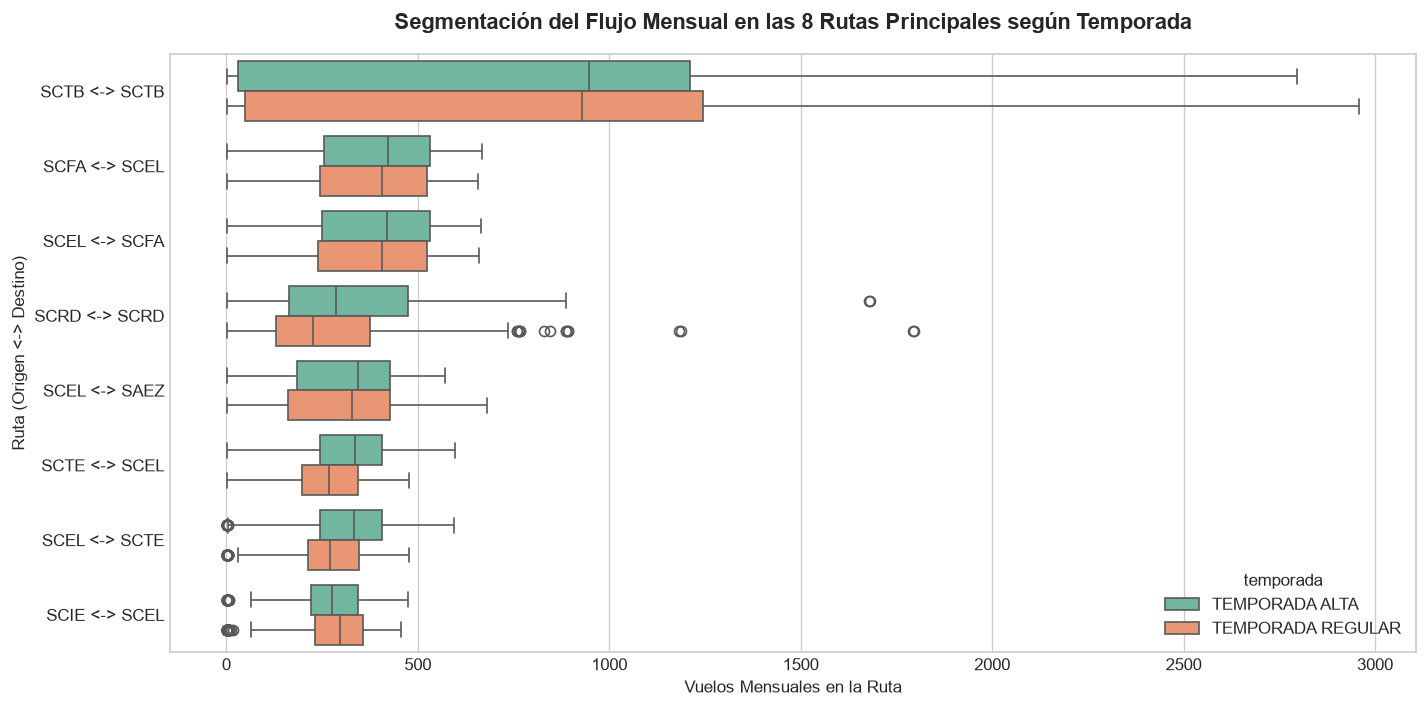

In [20]:
# PREPARACIÓN DE DATOS PARA SEABORN (Para no colapsar la RAM)
# Agrupamos los vuelos por ruta y mes
df_rutas_mes = df_clean.groupby(['periodo_ym', 'ruta', 'tipo_operacion', 'temporada'], as_index=False).agg(
    vuelos_mensuales=('dt_operacion', 'count')
)
df_rutas_mes = df_rutas_mes[df_rutas_mes['vuelos_mensuales'] > 0].copy()

# Aplicamos logaritmo base 10 porque hay rutas masivas y rutas de 1 solo vuelo
df_rutas_mes['log10_vuelos'] = np.log10(df_rutas_mes['vuelos_mensuales'])

# --- VISUALIZACIÓN 3 (SEABORN - DISTRIBUCIÓN): Histograma y Violinplot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

sns.histplot(data=df_rutas_mes, x='log10_vuelos', hue='tipo_operacion', kde=True, bins=35, ax=axes[0], alpha=0.5)
axes[0].set_title("Distribución de Vuelos Mensuales por Ruta (Escala Log10)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Log10(Vuelos Mensuales)")
axes[0].set_ylabel("Frecuencia (Cantidad de Registros)")

sns.violinplot(data=df_rutas_mes, x='tipo_operacion', y='log10_vuelos', hue='temporada', split=True, inner='quart', ax=axes[1])
axes[1].set_title("Densidad y Cuartiles por Tipo de Operación y Temporada", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Tipo de Operación")
axes[1].set_ylabel("Log10(Vuelos Mensuales)")

fig.suptitle("Estudio de Distribución, Asimetría y Dispersión del Tráfico Aéreo", fontsize=14, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}03_seaborn_distribucion.png", dpi=300, bbox_inches='tight')
plt.show()

# --- VISUALIZACIÓN 4 (SEABORN - SEGMENTACIÓN): Boxplot de Top 8 Rutas ---
top8_rutas = df_rutas_mes.groupby('ruta')['vuelos_mensuales'].sum().nlargest(8).index.tolist()
df_top8 = df_rutas_mes[df_rutas_mes['ruta'].isin(top8_rutas)]

fig, ax = plt.subplots(figsize=(12, 6), dpi=120)
sns.boxplot(data=df_top8, x='vuelos_mensuales', y='ruta', hue='temporada', order=top8_rutas, palette="Set2", ax=ax)
ax.set_title("Segmentación del Flujo Mensual en las 8 Rutas Principales según Temporada", fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel("Vuelos Mensuales en la Ruta")
ax.set_ylabel("Ruta (Origen <-> Destino)")

fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}04_seaborn_segmentacion_rutas.png", dpi=300)
plt.show()

### Análisis de Distribución (Parte XIV - Punto 35)
* **¿Dónde se concentra la información?:** La gran mayoría de los registros de rutas se concentra en la parte baja de la distribución (rutas con pocos vuelos al mes), lo que se evidencia en el gran pico del histograma entre 1 y 2 en escala $\log_{10}$ (es decir, entre 10 y 100 vuelos mensuales).
* **¿Existe asimetría?:** Sí, existe una severa **asimetría positiva (sesgo a la derecha)**. Hay miles de rutas con vuelos esporádicos y un puñado muy reducido de rutas con miles de vuelos mensuales. Por eso fue obligatorio aplicar $\log_{10}$.
* **¿Existe dispersión importante?:** Muy alta. El violinplot muestra que el tráfico nacional tiene mayor dispersión hacia arriba (rutas de alta densidad) en comparación con el tráfico internacional.
* **¿Existen posibles valores extremos?:** Sí, en el Boxplot observamos valores atípicos superiores (*outliers*). En el transporte, estos no son errores de tipeo, sino rutas troncales hipercentralizadas (por ejemplo, los puentes aéreos hacia Santiago).
* **¿Qué implicación tiene para el análisis?:** El uso de la media aritmética es engañoso para este sector; el análisis de tráfico aéreo debe basarse siempre en medianas y sumas segmentadas.

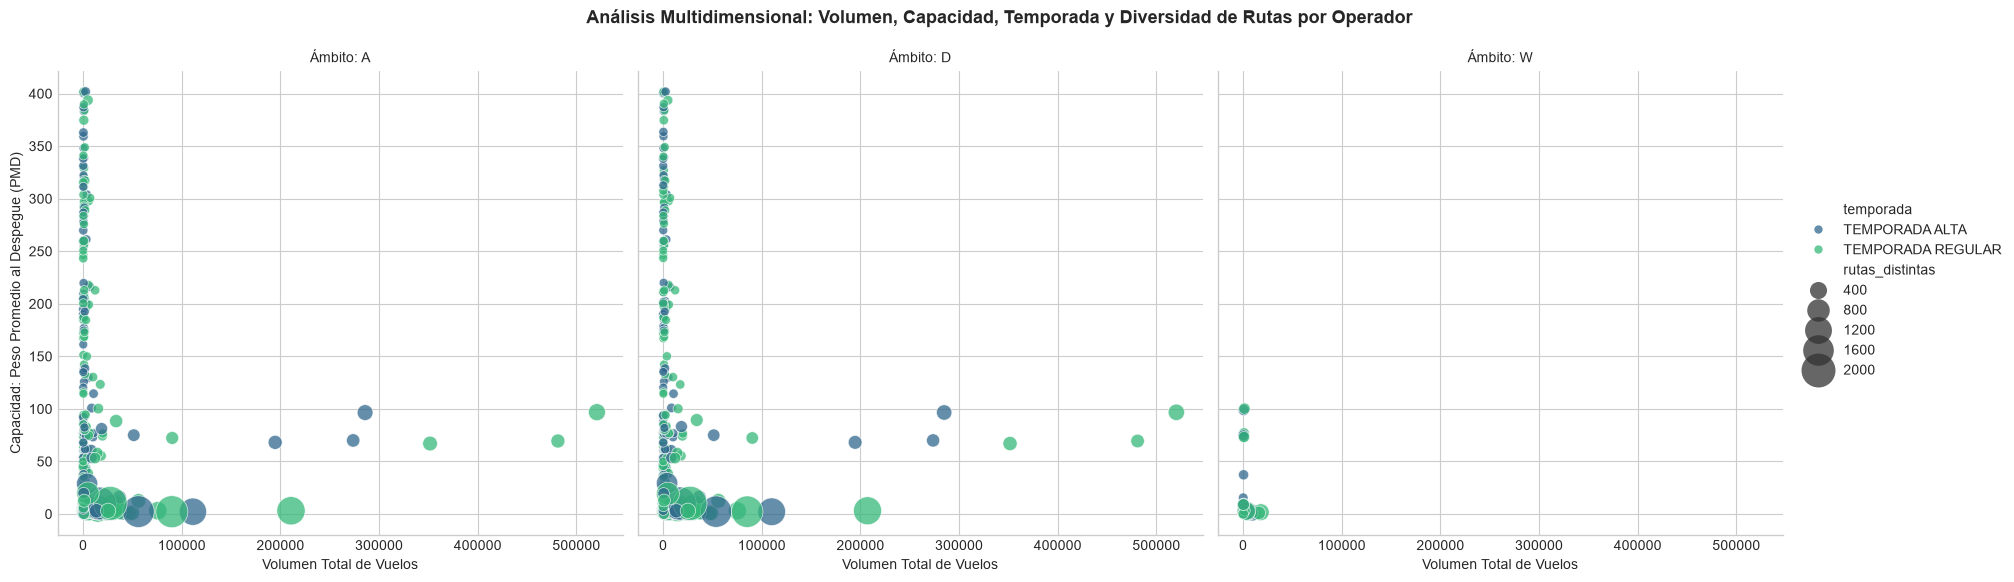

In [21]:
# PREPARACIÓN PARA MULTIDIMENSIONAL
# Agrupamos por Aerolínea, Tipo y Temporada para analizar la estrategia de los operadores
df_multi = df_clean.groupby(['aerolinea_dgac', 'tipo_operacion', 'temporada'], as_index=False).agg(
    total_vuelos=('dt_operacion', 'count'),
    peso_promedio=('pmd', 'mean'),
    rutas_distintas=('ruta', 'nunique')
)

# Filtramos operadores extremadamente pequeños para evitar que el gráfico se vuelva ilegible
df_multi = df_multi[df_multi['total_vuelos'] > 100].copy()

g = sns.relplot(
    data=df_multi,
    x='total_vuelos',
    y='peso_promedio',
    hue='temporada',
    size='rutas_distintas',
    col='tipo_operacion',
    sizes=(40, 600),
    alpha=0.75,
    palette='viridis',
    height=5.5,
    aspect=1.1
)

g.set_axis_labels("Volumen Total de Vuelos", "Capacidad: Peso Promedio al Despegue (PMD)")
g.set_titles("Ámbito: {col_name}")
g.fig.suptitle("Análisis Multidimensional: Volumen, Capacidad, Temporada y Diversidad de Rutas por Operador", fontsize=13, fontweight='bold', y=1.05)

g.savefig(f"{FIGURES_DIR}05_multidimensional_relplot.png", dpi=300, bbox_inches='tight')
plt.show()

### Justificación de Canales Visuales (Parte XV - Punto 37)
* **Variable A (`total_vuelos`) $\rightarrow$ Canal utilizado: Posición en eje X $\rightarrow$ Justificación:** La posición en un eje común es el canal visual más preciso para decodificar cantidades exactas; es ideal para la medida principal.
* **Variable B (`peso_promedio`) $\rightarrow$ Canal utilizado: Posición en eje Y $\rightarrow$ Justificación:** Permite formar un plano cartesiano bivariado que revela de inmediato si las aerolíneas con más vuelos también usan aviones más pesados (correlación).
* **Variable C (`rutas_distintas`) $\rightarrow$ Canal utilizado: Tamaño de burbuja (`size`) $\rightarrow$ Justificación:** El área de la figura transmite orgánicamente la idea de "magnitud secundaria" o expansión de la red de la aerolínea sin requerir gráficos 3D confusos.
* **Variable D (`temporada`) $\rightarrow$ Canal utilizado: Color (`hue`) $\rightarrow$ Justificación:** El tono cromático agrupa eficientemente las categorías nominales cualitativas, permitiendo ver si una misma aerolínea cambia de posición según la temporada.
* **Variable E (`tipo_operacion`) $\rightarrow$ Canal utilizado: Faceta/Subgráfico (`col`) $\rightarrow$ Justificación:** Divide el panel físicamente (*small multiples*) para evitar el colapso visual (*overplotting*) entre vuelos nacionales e internacionales.

#### ¿Qué ocurriría si incorporara una dimensión adicional?
Si se añadiera una sexta dimensión (por ejemplo, codificando una variable extra mediante la *forma del marcador*), se superaría el límite recomendado de carga cognitiva. El cerebro humano perdería la capacidad de procesamiento preatentivo, transformando el gráfico en un diagrama confuso donde obligaría al usuario a leer el gráfico punto por punto en lugar de identificar patrones generales de un vistazo.

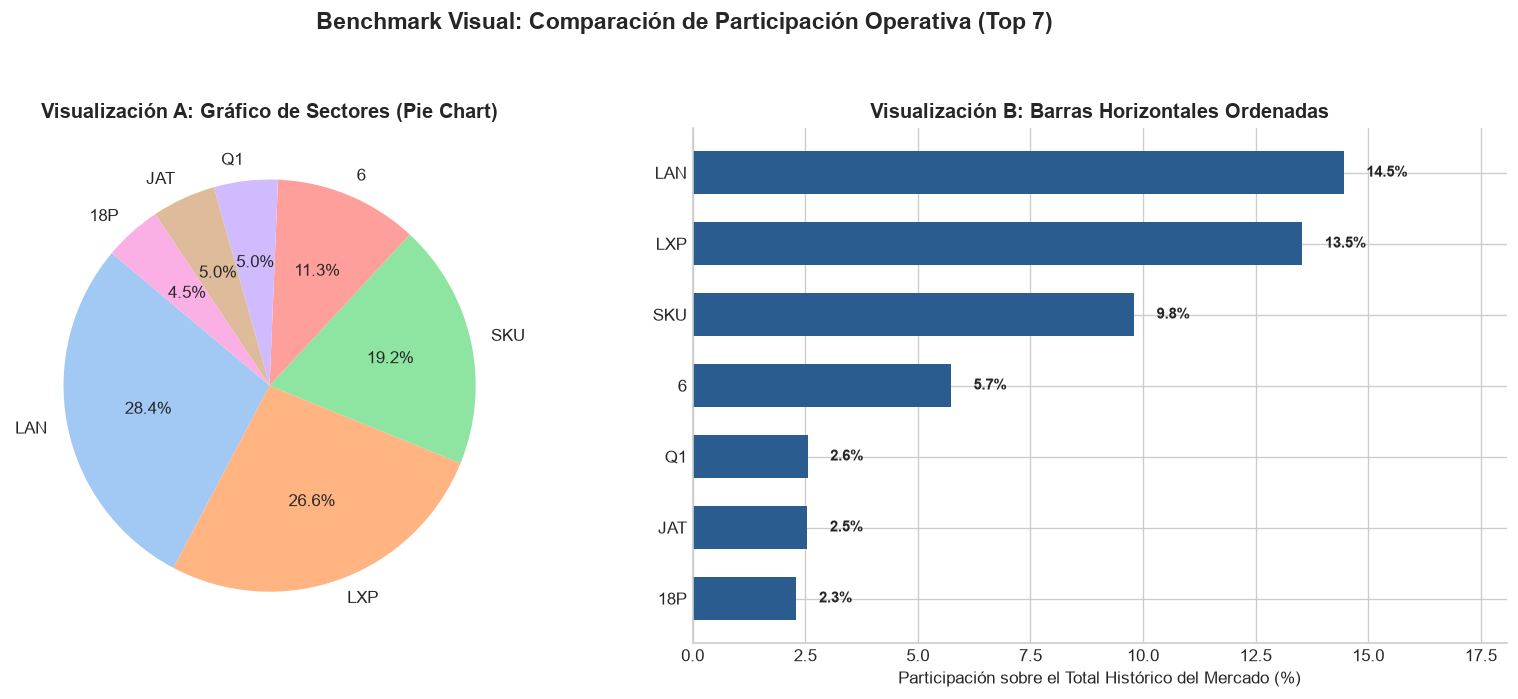

In [ ]:
# --- PARTE XVI: BENCHMARK VISUAL ---
# Pregunta analítica: ¿Cuál es la cuota de mercado del Top 7 de Aerolíneas operativas?
top7 = agg_simple.head(7).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

# Visualización A: Gráfico de Sectores (Pie Chart)
axes[0].pie(
    top7['total_vuelos'],
    labels=top7['aerolinea_dgac'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette("pastel")
)
axes[0].set_title("Visualización A: Gráfico de Sectores (Pie Chart)", fontsize=12, fontweight='bold')

# Visualización B: Gráfico de Barras Horizontales Ordenadas
top7_ord = top7.sort_values(by='participacion_pct', ascending=True)
axes[1].barh(top7_ord['aerolinea_dgac'], top7_ord['participacion_pct'], color='#2b5c8f', height=0.6)
for i, val in enumerate(top7_ord['participacion_pct']):
    axes[1].text(val + 0.5, i, f"{val:.1f}%", va='center', fontsize=9, fontweight='bold')

axes[1].set_title("Visualización B: Barras Horizontales Ordenadas", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Participación sobre el Total Histórico del Mercado (%)")
axes[1].set_xlim(0, top7_ord['participacion_pct'].max() * 1.25)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

fig.suptitle("Benchmark Visual: Comparación de Participación Operativa (Top 7)", fontsize=14, fontweight='bold', y=1.05)
fig.tight_layout()
fig.savefig(f"{FIGURES_DIR}06_benchmark_visual.png", dpi=300, bbox_inches='tight')
plt.show()

## PARTE XVI. Comparación del Benchmark Visual

| Criterio | Visualización A (Gráfico de Sectores / Pie Chart) | Visualización B (Barras Horizontales) |
| :--- | :--- | :--- |
| **Claridad** | Baja. Las rebanadas se agrupan visualmente y las etiquetas pueden colisionar si hay nombres largos. | Alta. La lectura es de izquierda a derecha (natural) sin cruce de textos. |
| **Precisión** | Muy baja. El cerebro humano es ineficiente estimando diferencias basadas en ángulos. | Muy Alta. Utiliza la longitud alineada en una escala común (cero). |
| **Comparabilidad** | Deficiente para distinguir la diferencia entre la 3.ª y 4.ª aerolínea. | Excelente. Permite ver diferencias de décimas porcentuales de un vistazo. |
| **Densidad informativa** | Baja. Obliga a recalcular el universo al 100% solo para esos 7 operadores. | Alta. Muestra el porcentaje real que tienen sobre el universo general (no suma 100% artificialmente). |
| **Carga cognitiva** | Alta. Obliga al lector a leer el texto porque las porciones no son autoexplicativas. | Muy Baja. La estructura gráfica resuelve el ranking preatentivamente. |
| **Utilidad** | Limitada a marketing básico. | Óptima para analítica descriptiva. |

### Decisión de Diseño: ¿Cuál debería utilizarse y por qué?
Se debe utilizar la **Visualización B (Barras Horizontales)**. El gráfico de sectores (A) introduce una distorsión estadística grave: al graficar un Top 7, fuerza que las porciones sumen 100%, mintiéndole al lector sobre la verdadera cuota de mercado al hacer desaparecer matemáticamente al resto de la industria. Las barras horizontales mantienen la proporción real e íntegra respecto al total del mercado, siendo perceptualmente superiores.

---

## PARTE XVII. Validación de las Dos Visualizaciones Definitivas Más Importantes

| Criterio de Auditoría | Visualización 1: Concentración Top 10 Aerolíneas | Visualización 2: Evolución Mensual por Operación |
| :--- | :--- | :--- |
| **Propósito** | Identificar qué aerolíneas dominan el volumen de operaciones históricas. | Detectar estacionalidad y comparar el volumen entre vuelos nacionales, internacionales, etc. |
| **Audiencia** | Reguladores (JAC, DGAC) y analistas de libre competencia. | Planificadores aeroportuarios y estrategas comerciales. |
| **Selección de datos** | Top 10 de aerolíneas derivado de `agg_simple`. | Serie temporal completa agrupada en `tabla_pivote`. |
| **Agregación** | Conteo absoluto de vuelos (`count`) y cálculo de %. | Conteo mensual de registros (`count`). |
| **Escalas** | Eje X Lineal, iniciando estrictamente en cero (expresado en miles). | Eje Y Lineal (expresado en miles) y Eje X cronológico ordenado. |
| **Color** | Focalizado: Azul para líderes de mercado, gris para atenuar al resto. | Categórico: Colores contrastantes para distinguir cada línea. |
| **Dimensiones** | 1 Dimensión (`aerolinea_dgac`) + 1 Medida (`total_vuelos`). | 2 Dimensiones (`periodo_ym`, `tipo_operacion`) + 1 Medida (`total_vuelos`). |
| **Legibilidad** | Máxima. El lector no cruza la mirada gracias a etiquetas directas. | Alta, aunque la superposición de líneas en meses valle exige mirar la leyenda. |
| **Integridad** | Respeta el 100% original en su denominador estadístico. | No interpola datos inventados; si un mes cae, cae en el gráfico. |
| **Posibles sesgos** | Oculta visualmente a las decenas de aerolíneas pequeñas que quedaron fuera del Top 10. | Al sumar todo Chile, oculta el hecho de que la mayoría del alza puede venir solo de Santiago. |
| **Potencial de error** | Creer que mayor volumen de vuelos = mayor cantidad de pasajeros (un vuelo masivo de Sky tiene más pasajeros que 3 vuelos de avionetas privadas). | Asumir una caída repentina como quiebra de industria, cuando solo puede ser un factor estacional o falta de reporte de datos en el último mes. |
| **Limitaciones** | Fotografía estática acumulada; no indica si la aerolínea dominante hoy está perdiendo fuerza. | Sensible a datos desfasados o meses parcialmente cargados por la JAC. |

## PARTE XVIII. Interpretación de Resultados (Hallazgos)

### HALLAZGO 1: Estructura altamente concentrada del mercado operativo
* **Datos utilizados:** Variable agregada `total_vuelos` cruzada por `aerolinea_dgac` (`agg_simple`).
* **Evidencia:** Las gráficas evidencian que un número minúsculo de operadores aéreos concentra la inmensa mayoría de las frecuencias de despegue y aterrizaje en Chile, dejando un remanente marginal para el resto de las decenas de operadores registrados.
* **Visualización:** `01_matplotlib_comparacion_operadores.png` y `06_benchmark_visual.png`.
* **Interpretación:** El sistema de aviación civil en Chile opera bajo una lógica de hub concentrado y oligopolio logístico. No significa ineficiencia, sino altas barreras de entrada por costos fijos.
* **Posible utilidad:** Focalizar las auditorías operativas y de seguridad en los 3 actores principales, ya que una disrupción en su malla paraliza el país.
* **Limitación:** El análisis mide frecuencias operativas (vuelos), no pasajes vendidos ni asientos ofrecidos.

### HALLAZGO 2: Patrón cíclico y estacionalidad dependiente de factores vacacionales
* **Datos utilizados:** Evolución temporal cruzada por `tipo_operacion` y `temporada` (`tabla_pivote`).
* **Evidencia:** Las gráficas de líneas muestran oscilaciones sistemáticas, con alzas consistentes hacia los meses de verano austral y un repunte menor a mitad de año, coincidiendo con la clasificación de "TEMPORADA ALTA".
* **Visualización:** `02_matplotlib_evolucion_temporal.png`.
* **Interpretación:** La demanda de infraestructura aeroportuaria está indexada al calendario vacacional escolar y turístico nacional, generando cuellos de botella temporales.
* **Posible utilidad:** Planificación flexible de personal de aduanas, DGAC y mantenimiento de pistas durante los meses "valle" de la temporada regular.
* **Limitación:** No se puede inferir qué días específicos de la semana son los más críticos.

### HALLAZGO 3: Polarización absoluta en la red de conectividad y dispersión de rutas
* **Datos utilizados:** Distribución de registros agregados por `ruta` en escala $\log_{10}$.
* **Evidencia:** El histograma y los boxplots demuestran que la mediana de vuelos mensuales por ruta es extremadamente baja frente al promedio, con una masa gigante de rutas esporádicas y un núcleo pequeñísimo de rutas troncales (outliers masivos).
* **Visualización:** `03_seaborn_distribucion.png` y `04_seaborn_segmentacion_rutas.png`.
* **Interpretación:** Chile carece de una conectividad regional transversal densa (ej: norte a sur directo). El modelo es del tipo radial (spoke-hub), donde casi todo alto flujo pasa obligadamente por el aeropuerto base principal.
* **Posible utilidad:** Justificar subsidios cruzados o políticas de promoción de vuelos interregionales directos.
* **Limitación:** No incorpora el análisis espacial en un mapa, lo que ayudaría a confirmar geográficamente el modelo radial.

---

## PARTE XIX. Ética Profesional

* **¿Qué decisión tomó?:** En la etapa de limpieza, tomé la decisión de eliminar los 1.122 registros exactamente duplicados (filas completas) sin consultarlo a la fuente original y de forzar los errores tipográficos en la columna de Peso Máximo (`pmd`) a `NaN`, para luego rellenarlos con `0`. Además, en gráficos como el multidimensional, oculté las aerolíneas con menos de 100 vuelos.
* **¿Qué evidencia la sustentó?:** En una base de datos transaccional estricta, un vuelo no puede repetirse con la misma hora exacta al microsegundo. En cuanto al PMD, una letra dentro del peso rompe cualquier función matemática posterior. Por el lado visual, más de 50 entidades superpuestas vuelven el gráfico inservible por saturación cognitiva.
* **¿Qué otra decisión pudo adoptar?:** Haber conservado los duplicados bajo la premisa de "nunca tocar la base cruda" o haber mantenido a todos los operadores en el gráfico multidimensional a expensas de la legibilidad.
* **¿Cómo afecta al resultado?:** Mi decisión disminuye marginalmente el conteo total histórico, pero aumenta drásticamente la fiabilidad de las métricas.
* **¿Puede modificar la percepción del lector?:** Sí. Al excluir a los micro-operadores del gráfico multidimensional, un ciudadano común podría pensar falsamente que los taxis aéreos, clubes de planeadores o vuelos de emergencia privados no existen en Chile.
* **¿Qué debería declarar al presentar el gráfico?:** Debo declarar mediante una anotación visible que la muestra estadística visual se restringe a *operadores mayores (n > 100 frecuencias)* y que los totales están purgados de ingresos administrativos duplicados.

---

## 13. Conclusiones Generales del Proyecto
1. La implementación de un flujo metodológico de datos demostró que la validación de tipos, nulos y duplicados no es opcional: es el fundamento técnico que evita representar gráficamente errores sistemáticos.
2. El formato de persistencia **Parquet** validó su superioridad técnica sobre el archivo de texto plano tradicional, logrando procesar más de 11 millones de operaciones con una fracción del costo computacional de memoria y almacenamiento.
3. Se corroboró visual y estadísticamente que el ecosistema aeronáutico en Chile está polarizado, marcado por una alta dependencia operacional en un hub principal, concentración en pocos actores, y ciclos de congestión predecibles en periodos estivales.